#PART 0 — Decide your language

In [ ]:
!pip install -q datasets tokenizers pandas numpy matplotlib

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset
from tokenizers import Tokenizer
from tokenizers.models import BPE, WordPiece
from tokenizers.trainers import BpeTrainer, WordPieceTrainer
from tokenizers.pre_tokenizers import Whitespace

In [ ]:
LANGUAGE = "hin_Deva"

print("Selected language:", LANGUAGE)

Selected language: hin_Deva


In [ ]:
#LOAD INDICCORPV2 HINDI DATA

from datasets import load_dataset

dataset = load_dataset(
    "ai4bharat/IndicCorpV2",
    "indiccorp_v2",
    split="hin_Deva",
    streaming=True
)

print(dataset)

IterableDataset({
    features: Unknown,
    num_shards: 3
})


In [ ]:
#Look at a few examples
for i, example in enumerate(dataset.take(5)):
    print(f"\nExample {i+1}:")
    print(example)


Example 1:
{'text': 'लोगों को बिलों संबंधी सुविधा देना ही उनका काम'}

Example 2:
{'text': ''}

Example 3:
{'text': 'इनेलो 1987 में उस वक्त ऐसे ही दोराहे पर खड़ी थी, जब पूर्व उपप्रधानमंत्री देवीलाल ने अपने पुत्र ओमप्रकाश चौटाला को अपना राजनीतिक उत्तराधिकारी घोषित किया था। हालांकि तब पार्टी पर देवीलाल की मजबूत पकड़ के चलते पार्टी टूटने से बच गई थी। 1989 में देवीलाल केन्द्र की राजनीति में सक्रिय हो गए थे और उनके उपप्रधानमंत्री बनने के पश्चात् उनके तीन बेटों जगदीश सिंह, रणजीत सिंह और ओमप्रकाश चौटाला में से रणजीत और ओमप्रकाश के बीच हरियाणा में उनकी राजनीतिक विरासत को लेकर जंग शुरू हो गई थी। उन परिस्थितियों में देवीलाल ने कड़ा निर्णय लेते हुए पार्टी की बागडोर ओमप्रकाश चौटाला के हवाले कर दी थी, जिसके बाद रणजीत की बगावत का असर पार्टी, संगठन और उनकी सरकार पर भी पड़ा था। उस समय रणजीत की नाराजगी के चलते उनके समर्थन में कई कैबिनेट मंत्रियों ने इस्तीफे दे दिए थे किन्तु तब पार्टी सुप्रीमो चौ. देवीलाल की हरियाणा की जनता पर इतनी मजबूत पकड़ थी कि ओमप्रकाश चौटाला को उत्तराधिकारी बनाने के उनके फैसले का 

In [ ]:
#Collect sentences
import re

def split_into_sentences(text):
    sentences = re.split(r'(?<=[।!?])\s+|(?<=[.!?])\s+', text)

    sentences = [
        s.strip()
        for s in sentences
        if s.strip()
    ]

    return sentences

In [ ]:
#Extract sentences from the corpus
MAX_SENTENCES = 1_005_000

sentences = []

for example in dataset:
    text = example["text"]

    new_sentences = split_into_sentences(text)
    sentences.extend(new_sentences)

    if len(sentences) >= MAX_SENTENCES:
        break

print("Total sentences collected:", len(sentences))

Total sentences collected: 1005000


In [ ]:
#Remove extremely short sentences
sentences = [
    s for s in sentences
    if len(s.split()) >= 3
]

print("Sentences after filtering:", len(sentences))

Sentences after filtering: 976228


In [ ]:
#Shuffle the sentences
import random
random.seed(42)
random.shuffle(sentences)
print("Shuffling completed.")

Shuffling completed.


In [ ]:
#Calculate sentence lengths
sentence_lengths = np.array([
    len(sentence.split())
    for sentence in sentences
])

print("Minimum length:", sentence_lengths.min())
print("Maximum length:", sentence_lengths.max())
print("Mean length:", sentence_lengths.mean())
print("Median length:", np.median(sentence_lengths))

Minimum length: 3
Maximum length: 1128
Mean length: 18.09618654658543
Median length: 16.0


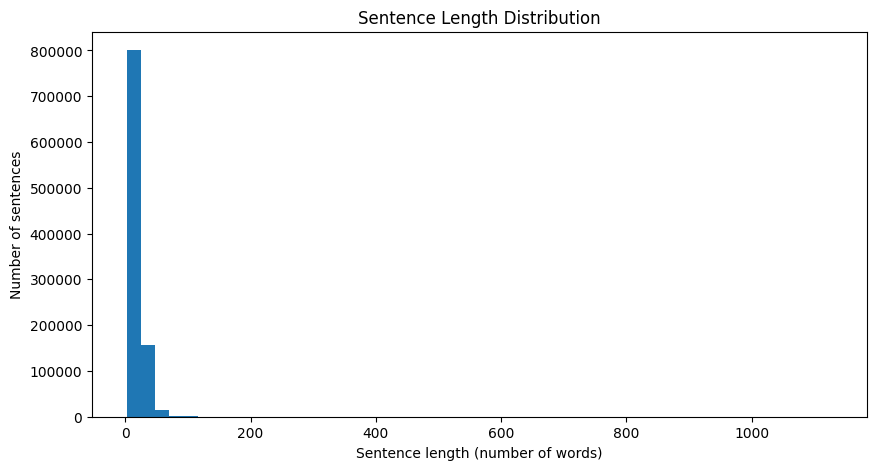

In [ ]:
#Visualize length distribution
plt.figure(figsize=(10, 5))

plt.hist(
    sentence_lengths,
    bins=50
)

plt.xlabel("Sentence length (number of words)")
plt.ylabel("Number of sentences")
plt.title("Sentence Length Distribution")

plt.show()

In [ ]:
#Create development and test sets
df = pd.DataFrame({
    "sentence": sentences,
    "length": sentence_lengths
})

df["length_bin"] = pd.qcut(
    df["length"],
    q=20,
    duplicates="drop"
)

print(df["length_bin"].value_counts().sort_index())

length_bin
(2.999, 6.0]      64641
(6.0, 7.0]        33007
(7.0, 9.0]        84614
(9.0, 10.0]       47984
(10.0, 11.0]      50079
(11.0, 12.0]      50988
(12.0, 13.0]      50743
(13.0, 14.0]      49143
(14.0, 15.0]      47253
(15.0, 16.0]      45004
(16.0, 17.0]      42094
(17.0, 18.0]      39659
(18.0, 19.0]      36266
(19.0, 21.0]      64284
(21.0, 22.0]      27223
(22.0, 25.0]      67875
(25.0, 27.0]      34746
(27.0, 31.0]      49834
(31.0, 37.0]      42812
(37.0, 1128.0]    47979
Name: count, dtype: int64


In [ ]:
# Sample development and test sentences while maintaining length distribution

dev_parts = []
test_parts = []

# Split each length bin proportionally
for _, group in df.groupby("length_bin", observed=True):

    n = len(group)

    # Number of samples from this bin
    dev_n = round(1000 * n / len(df))
    test_n = round(1000 * n / len(df))

    shuffled = group.sample(
        frac=1,
        random_state=42
    )

    # Take development sentences
    dev_parts.append(shuffled.iloc[:dev_n])

    # Take test sentences after development sentences
    test_parts.append(shuffled.iloc[dev_n:dev_n + test_n])

# Combine all bins
dev_df = pd.concat(dev_parts, ignore_index=True)
test_df = pd.concat(test_parts, ignore_index=True)

# If rounding caused the total to differ from 1000,
# randomly adjust to exactly 1000 samples
if len(dev_df) > 1000:
    dev_df = dev_df.sample(n=1000, random_state=42).reset_index(drop=True)
elif len(dev_df) < 1000:
    remaining = df[~df["text"].isin(dev_df["text"])]
    extra = remaining.sample(n=1000 - len(dev_df), random_state=42)
    dev_df = pd.concat([dev_df, extra], ignore_index=True)

if len(test_df) > 1000:
    test_df = test_df.sample(n=1000, random_state=123).reset_index(drop=True)
elif len(test_df) < 1000:
    remaining = df[
        ~df["text"].isin(set(dev_df["text"]) | set(test_df["text"]))
    ]
    extra = remaining.sample(n=1000 - len(test_df), random_state=123)
    test_df = pd.concat([test_df, extra], ignore_index=True)

# Final shuffle
dev_df = dev_df.sample(frac=1, random_state=42).reset_index(drop=True)
test_df = test_df.sample(frac=1, random_state=123).reset_index(drop=True)

print("Development sentences:", len(dev_df))
print("Test sentences:", len(test_df))

Development sentences: 1000
Test sentences: 1000


In [ ]:
#Create training data
remaining_df = df.drop(
    index=dev_df.index.union(test_df.index)
)

remaining_df = remaining_df.sample(
    frac=1,
    random_state=42
)

print("Remaining training sentences:", len(remaining_df))


Remaining training sentences: 975228


In [ ]:
#Create the four training sizes
TRAINING_SIZES = [
    100_000,
    300_000,
    500_000,
    1_000_000
]

training_sets = {}

for size in TRAINING_SIZES:
    training_sets[size] = remaining_df.iloc[:size]["sentence"].tolist()

    print(
        f"Training size {size:,}:",
        len(training_sets[size])
    )

Training size 100,000: 100000
Training size 300,000: 300000
Training size 500,000: 500000
Training size 1,000,000: 975228


In [ ]:
#Save the datasets
import os

os.makedirs("/content/indic_assignment_data", exist_ok=True)

for size, data in training_sets.items():

    path = f"/content/indic_assignment_data/train_{size}.txt"

    with open(path, "w", encoding="utf-8") as f:
        for sentence in data:
            f.write(sentence + "\n")

dev_path = "/content/indic_assignment_data/dev.txt"

with open(dev_path, "w", encoding="utf-8") as f:
    for sentence in dev_df["sentence"]:
        f.write(sentence + "\n")

test_path = "/content/indic_assignment_data/test.txt"

with open(test_path, "w", encoding="utf-8") as f:
    for sentence in test_df["sentence"]:
        f.write(sentence + "\n")

print("All datasets saved.")

All datasets saved.


In [ ]:
#Verify our split
print("TRAINING")

for size in TRAINING_SIZES:
    print(
        f"{size:,} sentences:",
        len(training_sets[size])
    )

print("\nDEVELOPMENT:")
print(len(dev_df))

print("\nTEST:")
print(len(test_df))

TRAINING
100,000 sentences: 100000
300,000 sentences: 300000
500,000 sentences: 500000
1,000,000 sentences: 975228

DEVELOPMENT:
1000

TEST:
1000


In [ ]:
#Check length distributions
print("TRAINING mean length:",
      remaining_df["length"].mean())

print("DEVELOPMENT mean length:",
      dev_df["length"].mean())

print("TEST mean length:",
      test_df["length"].mean())

print("\nTRAINING median:",
      remaining_df["length"].median())

print("DEVELOPMENT median:",
      dev_df["length"].median())

print("TEST median:",
      test_df["length"].median())

TRAINING mean length: 18.095454601385523
DEVELOPMENT mean length: 18.161
TEST mean length: 18.042

TRAINING median: 16.0
DEVELOPMENT median: 16.0
TEST median: 16.0


#PART 2 — BPE TOKENIZER

In [ ]:
#Function to train BPE
def train_bpe(training_file, vocab_size):

    tokenizer = Tokenizer(
        BPE(unk_token="[UNK]")
    )

    tokenizer.pre_tokenizer = Whitespace()

    trainer = BpeTrainer(
        vocab_size=vocab_size,
        min_frequency=2,
        special_tokens=["[UNK]"]
    )

    tokenizer.train(
        [training_file],
        trainer
    )

    return tokenizer

In [ ]:
#Function to train WordPiece
def train_wordpiece(training_file, vocab_size):

    tokenizer = Tokenizer(
        WordPiece(
            unk_token="[UNK]"
        )
    )

    tokenizer.pre_tokenizer = Whitespace()

    trainer = WordPieceTrainer(
        vocab_size=vocab_size,
        min_frequency=2,
        special_tokens=["[UNK]"]
    )

    tokenizer.train(
        [training_file],
        trainer
    )

    return tokenizer

#PART 3 — TRAINING SIZE EXPERIMENT

In [ ]:
#Train BPE on 100K
bpe_100k = train_bpe(
    "/content/indic_assignment_data/train_100000.txt",
    30_000
)

print("BPE 100K trained")
print("Vocabulary size:", bpe_100k.get_vocab_size())

BPE 100K trained
Vocabulary size: 30000


In [ ]:
#Train BPE on 300K
bpe_300k = train_bpe(
    "/content/indic_assignment_data/train_300000.txt",
    30_000
)

print("BPE 300K trained")
print("Vocabulary size:", bpe_300k.get_vocab_size())

BPE 300K trained
Vocabulary size: 30000


In [ ]:
#Train BPE on 500K
bpe_500k = train_bpe(
    "/content/indic_assignment_data/train_500000.txt",
    30_000
)

print("BPE 500K trained")
print("Vocabulary size:", bpe_500k.get_vocab_size())

BPE 500K trained
Vocabulary size: 30000


In [ ]:
#Train BPE on 1M
bpe_1m = train_bpe(
    "/content/indic_assignment_data/train_1000000.txt",
    30_000
)

print("BPE 1M trained")
print("Vocabulary size:", bpe_1m.get_vocab_size())

BPE 1M trained
Vocabulary size: 30000


#PART 4 — Test BPE tokenization

In [ ]:
sample_sentences = test_df["sentence"].head(5).tolist()

for i, sentence in enumerate(sample_sentences):

    encoding = bpe_1m.encode(sentence)

    print("\nSentence", i + 1)
    print(sentence)
    print("Tokens:")
    print(encoding.tokens)


Sentence 1
विश्वनाथन आनंद और राहुल गांधी ने दी बधाई
Tokens:
['विश्वनाथ', 'न', 'आनंद', 'और', 'राहुल', 'गांधी', 'ने', 'दी', 'बधाई']

Sentence 2
ये जानकारी एक सोर्स ने एंड्रॉयड सेंट्रल को दी है.
Tokens:
['ये', 'जानकारी', 'एक', 'सोर्स', 'ने', 'एंड्रॉयड', 'सेंट्रल', 'को', 'दी', 'है', '.']

Sentence 3
146126 लोग ठीक हो चुके हैं।
Tokens:
['146', '126', 'लोग', 'ठीक', 'हो', 'चुके', 'हैं', '।']

Sentence 4
बंद कराने निकले कांग्रेस नेता, बाजारों में घूमे और व्यापारियों से बंद में सहयोग करने की अपील की
Tokens:
['बंद', 'कराने', 'निकले', 'कांग्रेस', 'नेता', ',', 'बाजारों', 'में', 'घू', 'मे', 'और', 'व्यापारियों', 'से', 'बंद', 'में', 'सहयोग', 'करने', 'की', 'अपील', 'की']

Sentence 5
उन्होंने इसे कोर्ट के आदेशों की अवहेलना बताया।
Tokens:
['उन्होंने', 'इसे', 'कोर्ट', 'के', 'आदेशों', 'की', 'अवहेलना', 'बताया', '।']


In [ ]:
#Calculate average tokens per sentence
def average_tokens(tokenizer, sentences):

    total_tokens = 0

    for sentence in sentences:
        total_tokens += len(
            tokenizer.encode(sentence).tokens
        )

    return total_tokens / len(sentences)

In [ ]:
bpe_token_results = {}

for name, tokenizer in [
    ("100K", bpe_100k),
    ("300K", bpe_300k),
    ("500K", bpe_500k),
    ("1M", bpe_1m)
]:

    avg = average_tokens(
        tokenizer,
        test_df["sentence"].tolist()
    )

    bpe_token_results[name] = avg

    print(
        f"BPE {name}: {avg:.2f} tokens/sentence"
    )

BPE 100K: 21.02 tokens/sentence
BPE 300K: 20.97 tokens/sentence
BPE 500K: 20.96 tokens/sentence
BPE 1M: 20.96 tokens/sentence


#PART 5 — WORDPIECE

In [ ]:
#Train WordPiece on 100K

In [ ]:
wp_100k = train_wordpiece(
    "/content/indic_assignment_data/train_100000.txt",
    30_000
)

print("WordPiece 100K trained")
print("Vocabulary size:", wp_100k.get_vocab_size())

WordPiece 100K trained
Vocabulary size: 30000


In [ ]:
#300K
wp_300k = train_wordpiece(
    "/content/indic_assignment_data/train_300000.txt",
    30_000
)

print("WordPiece 300K trained")
print("Vocabulary size:", wp_300k.get_vocab_size())

WordPiece 300K trained
Vocabulary size: 30000


In [ ]:
#500K
wp_500k = train_wordpiece(
    "/content/indic_assignment_data/train_500000.txt",
    30_000
)

print("WordPiece 500K trained")
print("Vocabulary size:", wp_500k.get_vocab_size())

WordPiece 500K trained
Vocabulary size: 30000


In [ ]:
#1M
wp_1m = train_wordpiece(
    "/content/indic_assignment_data/train_1000000.txt",
    30_000
)

print("WordPiece 1M trained")
print("Vocabulary size:", wp_1m.get_vocab_size())

WordPiece 1M trained
Vocabulary size: 30000


In [ ]:
#Compare WordPiece
wp_token_results = {}

for name, tokenizer in [
    ("100K", wp_100k),
    ("300K", wp_300k),
    ("500K", wp_500k),
    ("1M", wp_1m)
]:

    avg = average_tokens(
        tokenizer,
        test_df["sentence"].tolist()
    )

    wp_token_results[name] = avg

    print(
        f"WordPiece {name}: {avg:.2f} tokens/sentence"
    )

WordPiece 100K: 21.18 tokens/sentence
WordPiece 300K: 21.12 tokens/sentence
WordPiece 500K: 21.12 tokens/sentence
WordPiece 1M: 21.13 tokens/sentence


In [ ]:
#Automatically train everything
VOCAB_SIZES = [
    20_000,
    30_000,
    50_000
]

results = []

for training_size in TRAINING_SIZES:

    training_file = (
        f"/content/indic_assignment_data/"
        f"train_{training_size}.txt"
    )

    for vocab_size in VOCAB_SIZES:

        print(
            f"\nTraining BPE | "
            f"Data={training_size:,} | "
            f"Vocab={vocab_size:,}"
        )

        tokenizer = train_bpe(
            training_file,
            vocab_size
        )

        avg_tokens = average_tokens(
            tokenizer,
            test_df["sentence"].tolist()
        )

        results.append({
            "Algorithm": "BPE",
            "Training Size": training_size,
            "Vocabulary Size": vocab_size,
            "Average Tokens": avg_tokens
        })


Training BPE | Data=100,000 | Vocab=20,000

Training BPE | Data=100,000 | Vocab=30,000

Training BPE | Data=100,000 | Vocab=50,000

Training BPE | Data=300,000 | Vocab=20,000

Training BPE | Data=300,000 | Vocab=30,000

Training BPE | Data=300,000 | Vocab=50,000

Training BPE | Data=500,000 | Vocab=20,000

Training BPE | Data=500,000 | Vocab=30,000

Training BPE | Data=500,000 | Vocab=50,000

Training BPE | Data=1,000,000 | Vocab=20,000

Training BPE | Data=1,000,000 | Vocab=30,000

Training BPE | Data=1,000,000 | Vocab=50,000


In [ ]:
#WordPiece experiments
for training_size in TRAINING_SIZES:

    training_file = (
        f"/content/indic_assignment_data/"
        f"train_{training_size}.txt"
    )

    for vocab_size in VOCAB_SIZES:

        print(
            f"\nTraining WordPiece | "
            f"Data={training_size:,} | "
            f"Vocab={vocab_size:,}"
        )

        tokenizer = train_wordpiece(
            training_file,
            vocab_size
        )

        avg_tokens = average_tokens(
            tokenizer,
            test_df["sentence"].tolist()
        )

        results.append({
            "Algorithm": "WordPiece",
            "Training Size": training_size,
            "Vocabulary Size": vocab_size,
            "Average Tokens": avg_tokens
        })


Training WordPiece | Data=100,000 | Vocab=20,000

Training WordPiece | Data=100,000 | Vocab=30,000

Training WordPiece | Data=100,000 | Vocab=50,000

Training WordPiece | Data=300,000 | Vocab=20,000

Training WordPiece | Data=300,000 | Vocab=30,000

Training WordPiece | Data=300,000 | Vocab=50,000

Training WordPiece | Data=500,000 | Vocab=20,000

Training WordPiece | Data=500,000 | Vocab=30,000

Training WordPiece | Data=500,000 | Vocab=50,000

Training WordPiece | Data=1,000,000 | Vocab=20,000

Training WordPiece | Data=1,000,000 | Vocab=30,000

Training WordPiece | Data=1,000,000 | Vocab=50,000


In [ ]:
#Create results table
results_df = pd.DataFrame(results)
results_df

,Algorithm,Training Size,Vocabulary Size,Average Tokens
0,BPE,100000,20000,21.532
1,BPE,100000,30000,21.020
2,BPE,100000,50000,20.633
3,BPE,300000,20000,21.483
4,BPE,300000,30000,20.969
5,BPE,300000,50000,20.545
6,BPE,500000,20000,21.495
7,BPE,500000,30000,20.956
8,BPE,500000,50000,20.532
9,BPE,1000000,20000,21.502


In [ ]:
#Save results
results_df.to_csv(
    "/content/indic_assignment_data/tokenization_results.csv",
    index=False
)

print("Results saved.")

Results saved.


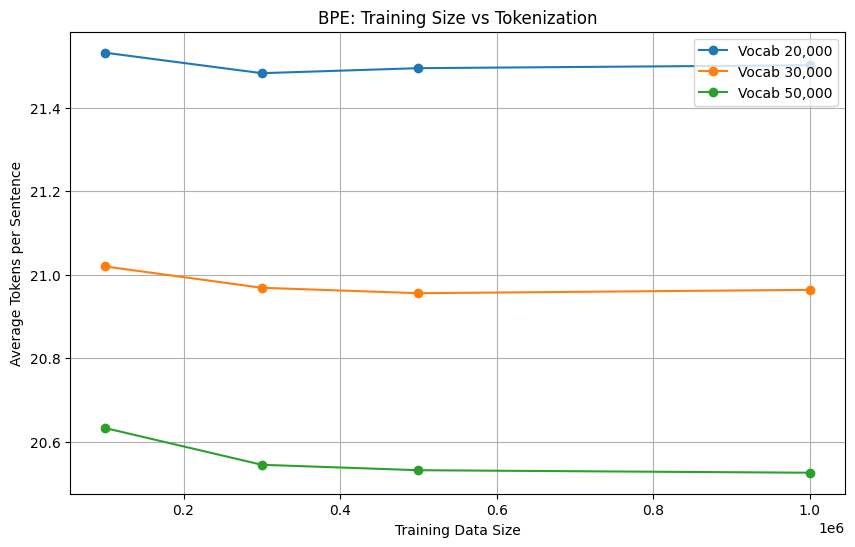

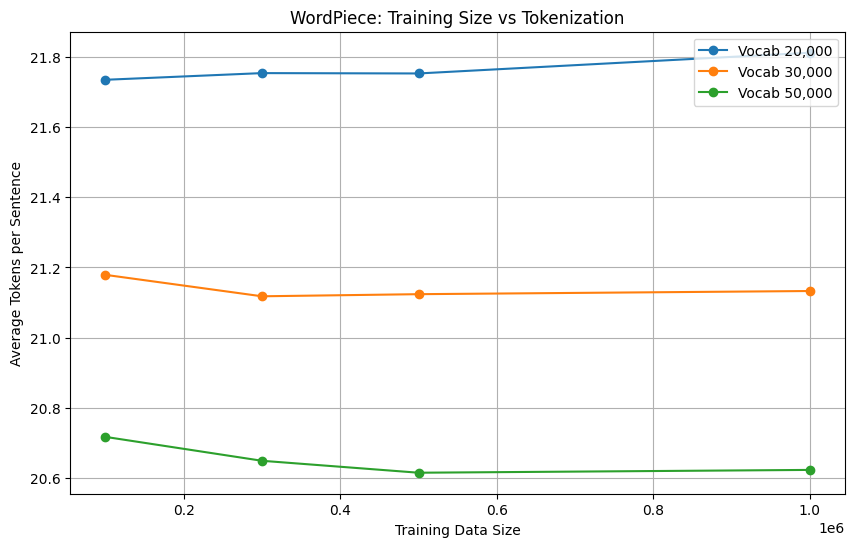

In [ ]:
#Plot vocabulary-size impact
for algorithm in ["BPE", "WordPiece"]:

    subset = results_df[
        results_df["Algorithm"] == algorithm
    ]

    plt.figure(figsize=(10, 6))

    for vocab_size in VOCAB_SIZES:

        data = subset[
            subset["Vocabulary Size"] == vocab_size
        ]

        plt.plot(
            data["Training Size"],
            data["Average Tokens"],
            marker="o",
            label=f"Vocab {vocab_size:,}"
        )

    plt.xlabel("Training Data Size")
    plt.ylabel("Average Tokens per Sentence")
    plt.title(f"{algorithm}: Training Size vs Tokenization")
    plt.legend()
    plt.grid(True)
    plt.show()

In [ ]:
#BPE vs WordPiece
comparison = results_df.pivot_table(
    index=["Training Size", "Vocabulary Size"],
    columns="Algorithm",
    values="Average Tokens"
)

comparison

Algorithm                         BPE  WordPiece
Training Size Vocabulary Size                   
100000        20000            21.532     21.734
              30000            21.020     21.179
              50000            20.633     20.718
300000        20000            21.483     21.753
              30000            20.969     21.118
              50000            20.545     20.650
500000        20000            21.495     21.752
              30000            20.956     21.124
              50000            20.532     20.616
1000000       20000            21.502     21.811
              30000            20.964     21.133
              50000            20.526     20.624

In [ ]:
#Save everything
results_df.to_csv(
    "/content/tokenization_results.csv",
    index=False
)

dev_df[["sentence"]].to_csv(
    "/content/dev_set.csv",
    index=False
)

test_df[["sentence"]].to_csv(
    "/content/test_set.csv",
    index=False
)

print("All files saved successfully.")

All files saved successfully.


#Assignment-4

In [ ]:
import math
from collections import Counter, defaultdict
import pandas as pd
import numpy as np

In [ ]:
# Check existing datasets

print("Training sentences:", len(remaining_df))
print("Development sentences:", len(dev_df))
print("Test sentences:", len(test_df))

print("\nSample training sentence:")
print(remaining_df["sentence"].iloc[0])

Training sentences: 975228
Development sentences: 1000
Test sentences: 1000

Sample training sentence:
इसके अलावा यूजर्स को लेख में गलत जानकारी को सही करने का विकल्प भी दिया गया है।


In [ ]:
# Tokenize sentences and add sentence boundary tokens

def tokenize(sentence):
    return ["<s>"] + str(sentence).split() + ["</s>"]

train_sentences = remaining_df["sentence"].tolist()
dev_sentences = dev_df["sentence"].tolist()
test_sentences = test_df["sentence"].tolist()

train_tokens = [tokenize(s) for s in train_sentences]
dev_tokens = [tokenize(s) for s in dev_sentences]
test_tokens = [tokenize(s) for s in test_sentences]

print("Training sentences:", len(train_tokens))
print("Development sentences:", len(dev_tokens))
print("Test sentences:", len(test_tokens))

print("\nSample tokenized sentence:")
print(train_tokens[0])

Training sentences: 975228
Development sentences: 1000
Test sentences: 1000

Sample tokenized sentence:
['<s>', 'इसके', 'अलावा', 'यूजर्स', 'को', 'लेख', 'में', 'गलत', 'जानकारी', 'को', 'सही', 'करने', 'का', 'विकल्प', 'भी', 'दिया', 'गया', 'है।', '</s>']


In [ ]:
# Build vocabulary from training data only

vocab = set()

for sentence in train_tokens:
    vocab.update(sentence)

V = len(vocab)

print("Vocabulary size:", V)
print("Sample vocabulary:", list(vocab)[:20])

Vocabulary size: 466537
Sample vocabulary: ['’’अमरनाथ', 'घंटाघर-अस्पताल', 'नार्गाजुन', 'Stora', '-पीडब्ल्यूडी', 'small', 'पिनों', 'पीलखानी', 'बेहट', 'सलुम्बर', 'अधिश्ठाता', 'तोड़ें', 'बसन्ती', 'तातीजा,', ',परमारकालीन', 'है।संयुक्त', 'विरु', 'कृष्णापुरा', '(2003),', '(एफयूपी)"']


In [ ]:
# Create n-gram frequency counts

ngram_counts = {
    1: Counter(),
    2: Counter(),
    3: Counter(),
    4: Counter()
}

for sentence in train_tokens:
    for n in range(1, 5):
        for i in range(len(sentence) - n + 1):
            ngram = tuple(sentence[i:i+n])
            ngram_counts[n][ngram] += 1

print("Unique unigrams:", len(ngram_counts[1]))
print("Unique bigrams:", len(ngram_counts[2]))
print("Unique trigrams:", len(ngram_counts[3]))
print("Unique quadgrams:", len(ngram_counts[4]))

Unique unigrams: 466537
Unique bigrams: 3893537
Unique trigrams: 9652032
Unique quadgrams: 13319725


In [ ]:
# Create context counts for bigram, trigram and quadgram models

context_counts = {
    2: Counter(),
    3: Counter(),
    4: Counter()
}

for n in range(2, 5):
    for ngram, count in ngram_counts[n].items():
        context = ngram[:-1]
        context_counts[n][context] += count

print("Bigram contexts:", len(context_counts[2]))
print("Trigram contexts:", len(context_counts[3]))
print("Quadgram contexts:", len(context_counts[4]))

Bigram contexts: 466536
Trigram contexts: 3849673
Quadgram contexts: 9452856


In [ ]:
# Unsmoothed probability

def unsmoothed_probability(ngram, n):
    if n == 1:
        count = ngram_counts[1].get((ngram[-1],), 0)
        total = sum(ngram_counts[1].values())
        return count / total if count > 0 else 0.0

    count = ngram_counts[n].get(tuple(ngram), 0)
    context = tuple(ngram[:-1])
    context_count = context_counts[n].get(context, 0)

    if count == 0 or context_count == 0:
        return 0.0

    return count / context_count

In [ ]:
# Calculate perplexity for an n-gram model

def calculate_perplexity(sentences, n, probability_function):
    log_probability = 0.0
    total_words = 0

    for sentence in sentences:
        for i in range(n - 1, len(sentence)):
            ngram = tuple(sentence[i-n+1:i+1])
            probability = probability_function(ngram, n)

            if probability == 0:
                return float("inf")

            log_probability += math.log(probability)
            total_words += 1

    return math.exp(-log_probability / total_words)

In [ ]:
# Unsmoothed perplexity for N = 1, 2, 3, 4

unsmoothed_results = {}

for n in range(1, 5):
    dev_ppl = calculate_perplexity(
        dev_tokens,
        n,
        unsmoothed_probability
    )

    test_ppl = calculate_perplexity(
        test_tokens,
        n,
        unsmoothed_probability
    )

    unsmoothed_results[n] = {
        "Development": dev_ppl,
        "Test": test_ppl
    }

    print(f"N={n}")
    print("  Development Perplexity:", dev_ppl)
    print("  Test Perplexity:", test_ppl)

N=1
  Development Perplexity: 1813.329396778466
  Test Perplexity: 1708.6886603776704
N=2
  Development Perplexity: 112.49555345709814
  Test Perplexity: 112.52602778418988
N=3
  Development Perplexity: 11.052982298102616
  Test Perplexity: 11.328656009511601
N=4
  Development Perplexity: 2.5108523032415877
  Test Perplexity: 2.565936528652577


In [ ]:
# Add-one (Laplace) smoothing

def add_one_probability(ngram, n):
    if n == 1:
        count = ngram_counts[1].get((ngram[-1],), 0)
        total = sum(ngram_counts[1].values())
        return (count + 1) / (total + V)

    count = ngram_counts[n].get(tuple(ngram), 0)
    context = tuple(ngram[:-1])
    context_count = context_counts[n].get(context, 0)

    return (count + 1) / (context_count + V)

In [ ]:
# Perplexity using Add-one smoothing

add_one_results = {}

for n in range(1, 5):
    dev_ppl = calculate_perplexity(
        dev_tokens,
        n,
        add_one_probability
    )

    test_ppl = calculate_perplexity(
        test_tokens,
        n,
        add_one_probability
    )

    add_one_results[n] = {
        "Development": dev_ppl,
        "Test": test_ppl
    }

    print(f"N={n}")
    print("  Development Perplexity:", dev_ppl)
    print("  Test Perplexity:", test_ppl)

N=1
  Development Perplexity: 1823.1937067206145
  Test Perplexity: 1718.79355843303
N=2
  Development Perplexity: 6467.976016288527
  Test Perplexity: 6116.261370265797
N=3
  Development Perplexity: 58431.31349219786
  Test Perplexity: 56933.56692552392
N=4
  Development Perplexity: 146758.0141007915
  Test Perplexity: 146013.39504998468


In [ ]:
# Add-K smoothing
# K must satisfy 0 < K < 1

K = 0.1

def add_k_probability(ngram, n):
    if n == 1:
        count = ngram_counts[1].get((ngram[-1],), 0)
        total = sum(ngram_counts[1].values())
        return (count + K) / (total + K * V)

    count = ngram_counts[n].get(tuple(ngram), 0)
    context = tuple(ngram[:-1])
    context_count = context_counts[n].get(context, 0)

    return (count + K) / (context_count + K * V)

In [ ]:
# Perplexity using Add-K smoothing

add_k_results = {}

for n in range(1, 5):
    dev_ppl = calculate_perplexity(
        dev_tokens,
        n,
        add_k_probability
    )

    test_ppl = calculate_perplexity(
        test_tokens,
        n,
        add_k_probability
    )

    add_k_results[n] = {
        "Development": dev_ppl,
        "Test": test_ppl
    }

    print(f"N={n}")
    print("  Development Perplexity:", dev_ppl)
    print("  Test Perplexity:", test_ppl)

N=1
  Development Perplexity: 1813.513336433531
  Test Perplexity: 1708.9507171214905
N=2
  Development Perplexity: 1305.7363337301456
  Test Perplexity: 1240.0512457062755
N=3
  Development Perplexity: 8463.81284943254
  Test Perplexity: 8229.124221889964
N=4
  Development Perplexity: 23920.7369674676
  Test Perplexity: 23781.67110467683


In [ ]:
# Interpolated smoothing

LAMBDA = 0.7

def interpolated_probability(ngram, n):
    if n == 1:
        count = ngram_counts[1].get((ngram[-1],), 0)
        total = sum(ngram_counts[1].values())
        return count / total if count > 0 else 0.0

    # Higher-order probability
    count = ngram_counts[n].get(tuple(ngram), 0)
    context = tuple(ngram[:-1])
    context_count = context_counts[n].get(context, 0)

    if context_count > 0:
        p_n = count / context_count
    else:
        p_n = 0.0

    # Lower-order probability
    p_lower = interpolated_probability(ngram[1:], n - 1)

    return LAMBDA * p_n + (1 - LAMBDA) * p_lower

In [ ]:
# Perplexity using Interpolated smoothing

interpolated_results = {}

for n in range(1, 5):
    dev_ppl = calculate_perplexity(
        dev_tokens,
        n,
        interpolated_probability
    )

    test_ppl = calculate_perplexity(
        test_tokens,
        n,
        interpolated_probability
    )

    interpolated_results[n] = {
        "Development": dev_ppl,
        "Test": test_ppl
    }

    print(f"N={n}")
    print("  Development Perplexity:", dev_ppl)
    print("  Test Perplexity:", test_ppl)

N=1
  Development Perplexity: 1813.329396778466
  Test Perplexity: 1708.6886603776704
N=2
  Development Perplexity: 144.89416504577815
  Test Perplexity: 144.58587450660931
N=3
  Development Perplexity: 13.988909095114325
  Test Perplexity: 14.289172319549165
N=4
  Development Perplexity: 3.0715190121537295
  Test Perplexity: 3.1368908133557043


In [ ]:
# Kneser-Ney smoothing statistics

D = 0.75

# Number of unique continuations for each context
kn_unique_followers = {}

for n in range(2, 5):
    followers = defaultdict(set)

    for ngram in ngram_counts[n]:
        context = ngram[:-1]
        word = ngram[-1]
        followers[context].add(word)

    kn_unique_followers[n] = {
        context: len(words)
        for context, words in followers.items()
    }

# Continuation counts for lower-order distributions
kn_continuation_counts = Counter()

for bigram in ngram_counts[2]:
    word = bigram[-1]
    kn_continuation_counts[word] += 1

total_unique_bigrams = len(ngram_counts[2])

print("Unique bigrams:", total_unique_bigrams)
print("Words with continuation counts:", len(kn_continuation_counts))

Unique bigrams: 3893537
Words with continuation counts: 466536


In [ ]:
# Interpolated Kneser-Ney probability

def kneser_ney_probability(ngram, n):
    ngram = tuple(ngram)

    # Base distribution for unigram
    if n == 1:
        continuation_count = kn_continuation_counts.get(ngram[-1], 0)

        if total_unique_bigrams == 0:
            return 0.0

        return continuation_count / total_unique_bigrams

    context = ngram[:-1]
    word = ngram[-1]

    count = ngram_counts[n].get(ngram, 0)
    context_count = context_counts[n].get(context, 0)

    # If context was never seen
    if context_count == 0:
        return kneser_ney_probability(ngram[1:], n - 1)

    # Discounted probability
    first_term = max(count - D, 0) / context_count

    # Number of unique words following this context
    unique_followers = kn_unique_followers[n].get(context, 0)

    lambda_context = (D * unique_followers) / context_count

    # Lower-order probability
    lower_probability = kneser_ney_probability(
        ngram[1:],
        n - 1
    )

    return first_term + lambda_context * lower_probability

In [ ]:
# Perplexity using Kneser-Ney smoothing

kneser_ney_results = {}

for n in range(1, 5):
    dev_ppl = calculate_perplexity(
        dev_tokens,
        n,
        kneser_ney_probability
    )

    test_ppl = calculate_perplexity(
        test_tokens,
        n,
        kneser_ney_probability
    )

    kneser_ney_results[n] = {
        "Development": dev_ppl,
        "Test": test_ppl
    }

    print(f"N={n}")
    print("  Development Perplexity:", dev_ppl)
    print("  Test Perplexity:", test_ppl)

N=1
  Development Perplexity: inf
  Test Perplexity: inf
N=2
  Development Perplexity: 140.23942814068977
  Test Perplexity: 139.3918784667969
N=3
  Development Perplexity: 19.11523854594506
  Test Perplexity: 19.400828818666376
N=4
  Development Perplexity: 5.136266987955402
  Test Perplexity: 5.236835586506876


In [ ]:
# Compare all language models

results = []

methods = {
    "Unsmoothed": unsmoothed_results,
    "Add-One": add_one_results,
    "Add-K (K=0.1)": add_k_results,
    "Interpolated (λ=0.7)": interpolated_results,
    "Kneser-Ney (d=0.75)": kneser_ney_results
}

for method, values in methods.items():
    for n in range(1, 5):
        results.append({
            "Model": f"{n}-gram",
            "Smoothing": method,
            "Development Perplexity": values[n]["Development"],
            "Test Perplexity": values[n]["Test"]
        })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

 Model            Smoothing  Development Perplexity  Test Perplexity
1-gram           Unsmoothed            1.813329e+03     1.708689e+03
2-gram           Unsmoothed            1.124956e+02     1.125260e+02
3-gram           Unsmoothed            1.105298e+01     1.132866e+01
4-gram           Unsmoothed            2.510852e+00     2.565937e+00
1-gram              Add-One            1.823194e+03     1.718794e+03
2-gram              Add-One            6.467976e+03     6.116261e+03
3-gram              Add-One            5.843131e+04     5.693357e+04
4-gram              Add-One            1.467580e+05     1.460134e+05
1-gram        Add-K (K=0.1)            1.813513e+03     1.708951e+03
2-gram        Add-K (K=0.1)            1.305736e+03     1.240051e+03
3-gram        Add-K (K=0.1)            8.463813e+03     8.229124e+03
4-gram        Add-K (K=0.1)            2.392074e+04     2.378167e+04
1-gram Interpolated (λ=0.7)            1.813329e+03     1.708689e+03
2-gram Interpolated (λ=0.7)       

In [ ]:
# Find the best performing models

print("Best Development model:")
print(
    results_df.loc[
        results_df["Development Perplexity"].idxmin()
    ]
)

print("\nBest Test model:")
print(
    results_df.loc[
        results_df["Test Perplexity"].idxmin()
    ]
)

Best Development model:
Model                         4-gram
Smoothing                 Unsmoothed
Development Perplexity      2.510852
Test Perplexity             2.565937
Name: 3, dtype: object

Best Test model:
Model                         4-gram
Smoothing                 Unsmoothed
Development Perplexity      2.510852
Test Perplexity             2.565937
Name: 3, dtype: object
